<h1>EDA, dataset <i>tiny</i></h1>
<p>Análise exploratória do dataset <i>tiny</i> (distrito de Braga e Póvoa de Varzim) usado no projeto de IA. O notebook
<code>02_eda_tiny.ipynb</code> e o <code>02_eda_small.ipynb</code> têm o mesmo código: só muda a variável <code>DATA</code>.</p>
<p><b>Objetivos:</b> (i) ler as regras do <code>rules.csv</code>; (ii) validar a integridade dos dados e a coerência das janelas de tempo;
(iii) comparar pesos com capacidades; (iv) verificar a refrigeração e a velocidade; (v) estudar a geografia e a matriz de distâncias;
(vi) avaliar a viabilidade de cada pedido e a estrutura temporal, para fundamentar o modelo do <code>01_Project01_G13.ipynb</code>.</p>
<p><b>Terminologia:</b> uma <b>encomenda</b> é composta por um ou mais <b>pedidos</b>; cada pedido é uma linha de <code>order_items</code>
(um produto de um produtor, com peso, janela de recolha e janela de entrega).</p>

<h2>1. Dados e regras</h2>

In [1]:
from pathlib import Path
import math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from model import load_rules

DATA = Path("data_tiny")                      # único parâmetro que muda entre o EDA do tiny e o do small
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
names = ["localities", "producers", "collection_centers", "customers", "delivery_locations", "locations",
         "products", "vehicles", "orders", "order_items", "distance_matrix"]
dt_cols = {"order_items": ["availability_start", "availability_end", "delivery_start", "delivery_end"], "orders": ["order_datetime"]}
df = {n: pd.read_csv(DATA / f"{n}.csv", parse_dates=dt_cols.get(n, [])) for n in names}
rules = load_rules(DATA)
print("Regras lidas de:", rules.source)
display(pd.DataFrame({n: {"linhas": len(d), "colunas": d.shape[1]} for n, d in df.items()}).T)
rules.table()

Regras lidas de: data_tiny/rules.csv


,linhas,colunas
localities,49,6
producers,3,6
collection_centers,1,5
customers,12,5
delivery_locations,5,5
locations,9,7
products,15,6
vehicles,2,6
orders,12,5
order_items,40,9


,regra,valor
0,start_date,2026-10-30
1,horizon_days,2
2,flow,producer>warehouse>delivery_location
3,stop_service_min,10.0
4,warehouse_handling_min,15.0
5,max_warehouse_dwell_h,24.0
6,window_semantics,service_start
7,avg_speed_kmh,45.0
8,route_factor,1.3
9,generator_seed,1


<p>O dataset tem 3 produtores, 1 centro de recolha, 2 veículos, 5 locais de entrega, 12 encomendas e 40 pedidos, e traz um ficheiro novo, <code>rules.csv</code>, com as regras do problema. O horizonte são <b>2 dias</b> (30 e 31/10/2026). Todo o produto passa pelo armazém; cada paragem de recolha ou de entrega demora <b>10 min</b> (<code>stop_service_min</code>); descarregar e carregar no armazém demora <b>15 min</b> (<code>warehouse_handling_min</code>); um produto pode ficar no armazém no máximo <b>24 h</b>; e as janelas limitam o <b>início</b> do serviço. A velocidade (45 km/h) e o fator de estrada (1.3) são os usados para construir a matriz de distâncias.</p>

<h2>2. Integridade dos dados</h2>

In [2]:
checks = pd.DataFrame({n: {"valores em falta": int(d.isna().sum().sum()), "linhas duplicadas": int(d.duplicated().sum())} for n, d in df.items()}).T
display(checks)

# Chaves estrangeiras: cada referência tem de existir na tabela de origem
fks = [("producers", "locality_id", "localities", "locality_id"), ("customers", "locality_id", "localities", "locality_id"),
       ("collection_centers", "locality_id", "localities", "locality_id"), ("delivery_locations", "locality_id", "localities", "locality_id"),
       ("products", "producer_id", "producers", "producer_id"), ("vehicles", "center_id", "collection_centers", "center_id"),
       ("orders", "customer_id", "customers", "customer_id"), ("orders", "delivery_location_id", "delivery_locations", "delivery_location_id"),
       ("order_items", "order_id", "orders", "order_id"), ("order_items", "product_id", "products", "product_id"),
       ("distance_matrix", "origin_location_id", "locations", "location_id"), ("distance_matrix", "destination_location_id", "locations", "location_id")]
res = [(a, ca, b, cb, int((~df[a][ca].isin(df[b][cb])).sum())) for a, ca, b, cb in fks]
display(pd.DataFrame(res, columns=["tabela", "coluna", "referencia", "chave", "referências inválidas"]))

# weight_kg tem de ser igual a quantity × unit_weight_kg
it = (df["order_items"].merge(df["products"], on="product_id").merge(df["orders"], on="order_id")
      .merge(df["producers"][["producer_id", "name"]].rename(columns={"name": "producer"}), on="producer_id"))
calc = it.quantity * it.unit_weight_kg
print("weight_kg = quantity × unit_weight_kg em todos os pedidos:", bool(np.allclose(it.weight_kg, calc, atol=0.05)),
      f"(diferença máxima {abs(it.weight_kg - calc).max():.3f} kg)")
print("Estados das encomendas:", df["orders"].status.value_counts().to_dict())

,valores em falta,linhas duplicadas
localities,0,0
producers,0,0
collection_centers,0,0
customers,0,0
delivery_locations,0,0
locations,0,0
products,0,0
vehicles,0,0
orders,0,0
order_items,0,0


,tabela,coluna,referencia,chave,referências inválidas
0,producers,locality_id,localities,locality_id,0
1,customers,locality_id,localities,locality_id,0
2,collection_centers,locality_id,localities,locality_id,0
3,delivery_locations,locality_id,localities,locality_id,0
4,products,producer_id,producers,producer_id,0
5,vehicles,center_id,collection_centers,center_id,0
6,orders,customer_id,customers,customer_id,0
7,orders,delivery_location_id,delivery_locations,delivery_location_id,0
8,order_items,order_id,orders,order_id,0
9,order_items,product_id,products,product_id,0


weight_kg = quantity × unit_weight_kg em todos os pedidos: True (diferença máxima 0.000 kg)
Estados das encomendas: {'confirmed': 12}


<p><b>Conclusão:</b> não há valores em falta, duplicados nem referências inválidas (incluindo os <code>location_id</code> da matriz). A coluna nova <code>weight_kg</code> coincide com <code>quantity × unit_weight_kg</code>, por isso o modelo usa a diretamente. As 12 encomendas estão todas <i>confirmed</i>.</p>

<h2>3. Encomendas e pedidos</h2>

12 encomendas, 40 pedidos, 3 produtores usados, 5 locais de entrega usados
Pedidos por encomenda: mínimo 2 | máximo 5 | média 3.3
Peso por pedido: 1.8 a 20.3 kg (média 6.8 kg)
Janelas de recolha: 1.75 a 4 h | janelas de entrega: 1.5 a 3.75 h


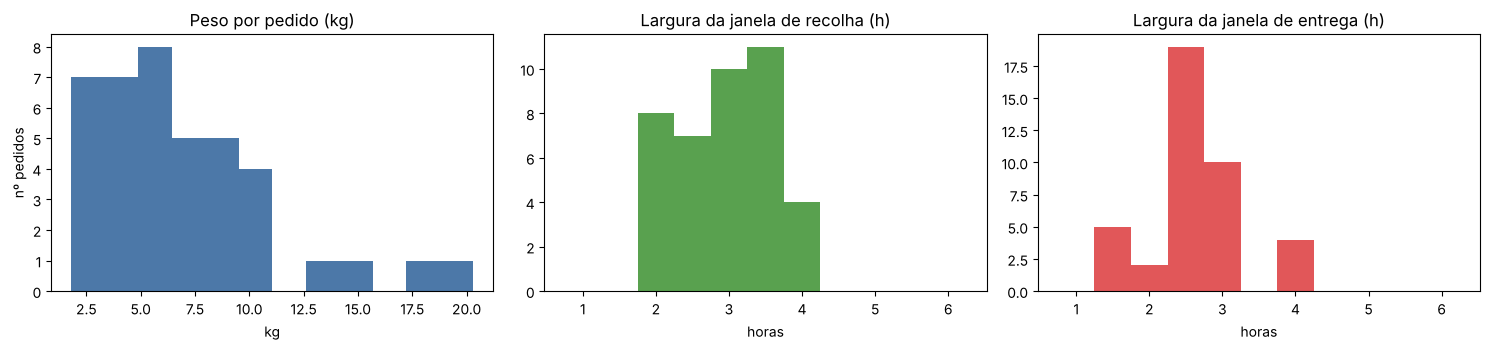

In [3]:
it["avail_h"] = (it.availability_end - it.availability_start).dt.total_seconds() / 3600
it["deliv_h"] = (it.delivery_end - it.delivery_start).dt.total_seconds() / 3600
print(f"{len(df['orders'])} encomendas, {len(it)} pedidos, {it.producer_id.nunique()} produtores usados, "
      f"{it.delivery_location_id.nunique()} locais de entrega usados")
print("Pedidos por encomenda: mínimo", it.groupby("order_id").size().min(), "| máximo", it.groupby("order_id").size().max(),
      "| média", round(it.groupby("order_id").size().mean(), 1))
print(f"Peso por pedido: {it.weight_kg.min():.1f} a {it.weight_kg.max():.1f} kg (média {it.weight_kg.mean():.1f} kg)")
print(f"Janelas de recolha: {it.avail_h.min():g} a {it.avail_h.max():g} h | janelas de entrega: {it.deliv_h.min():g} a {it.deliv_h.max():g} h")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(it.weight_kg, bins=12, color="#4c78a8"); ax[0].set(title="Peso por pedido (kg)", xlabel="kg", ylabel="nº pedidos")
ax[1].hist(it.avail_h, bins=np.arange(0.75, 6.5, 0.5), color="#59a14f"); ax[1].set(title="Largura da janela de recolha (h)", xlabel="horas")
ax[2].hist(it.deliv_h, bins=np.arange(0.75, 6.5, 0.5), color="#e15759"); ax[2].set(title="Largura da janela de entrega (h)", xlabel="horas")
plt.tight_layout(); plt.show()

<p>Cada encomenda tem 2 a 5 pedidos (3.3 em média) e cada pedido pesa entre 1.8 e 20.3 kg. As janelas de recolha têm 1.75 a 4 h e as de entrega 1.5 a 3.75 h. Como uma encomenda tem vários pedidos para o mesmo local de entrega, e um produtor tem vários pedidos com janelas parecidas, é frequente servir vários artigos na mesma paragem: por isso o modelo cobra o serviço de 10 min <b>por paragem</b> e não por artigo.</p>

<h2>4. Janelas de tempo</h2>

,todos os pedidos?
recolha: início < fim,True
entrega: início < fim,True
entrega_fim > recolha_início,True
"todas as janelas dentro do horizonte [30/10, 01/11[",True


Dias com recolhas: ['30/10', '31/10'] | dias com entregas: ['30/10', '31/10']
Pedidos entregues no dia seguinte à recolha: 10 de 40
Intervalo entre o fim da recolha e o início da entrega: -1.50 a 23.75 h (limite no armazém: 24 h)
Pedidos com a entrega a abrir antes de fechar a recolha (intervalo negativo): 10
order_datetime posterior ao início da recolha em 0% dos pedidos


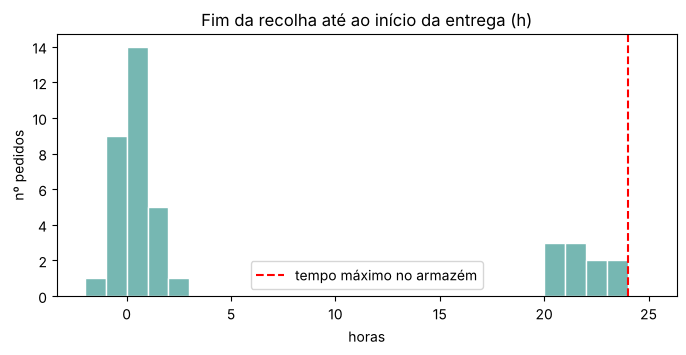

In [4]:
start = pd.Timestamp(rules.start_date) if rules.start_date else it.availability_start.min().normalize()
end = start + pd.Timedelta(days=rules.horizon_days or 1)
t = pd.Series({
    "recolha: início < fim": (it.availability_start < it.availability_end).all(),
    "entrega: início < fim": (it.delivery_start < it.delivery_end).all(),
    "entrega_fim > recolha_início": (it.delivery_end > it.availability_start).all(),
    f"todas as janelas dentro do horizonte [{start:%d/%m}, {end:%d/%m}[": ((it.availability_start >= start) & (it.delivery_end <= end)).all(),
}, name="todos os pedidos?")
display(t.to_frame())
it["gap_h"] = (it.delivery_start - it.availability_end).dt.total_seconds() / 3600
it["next_day"] = it.delivery_start.dt.normalize() > it.availability_start.dt.normalize()
print("Dias com recolhas:", sorted(it.availability_start.dt.strftime("%d/%m").unique()),
      "| dias com entregas:", sorted(it.delivery_start.dt.strftime("%d/%m").unique()))
print(f"Pedidos entregues no dia seguinte à recolha: {int(it.next_day.sum())} de {len(it)}")
print(f"Intervalo entre o fim da recolha e o início da entrega: {it.gap_h.min():.2f} a {it.gap_h.max():.2f} h "
      f"(limite no armazém: {rules.max_warehouse_dwell_h:g} h)")
print(f"Pedidos com a entrega a abrir antes de fechar a recolha (intervalo negativo): {int((it.gap_h < 0).sum())}")
print(f"order_datetime posterior ao início da recolha em {(it.order_datetime > it.availability_start).mean():.0%} dos pedidos")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(it.gap_h, bins=np.arange(-2, 26, 1), color="#76b7b2", edgecolor="w")
ax.axvline(rules.max_warehouse_dwell_h if math.isfinite(rules.max_warehouse_dwell_h) else 0, color="red", ls="--", label="tempo máximo no armazém")
ax.set(title="Fim da recolha até ao início da entrega (h)", xlabel="horas", ylabel="nº pedidos"); ax.legend(); plt.show()

<p>As janelas são coerentes e estão todas dentro do horizonte de 2 dias. <b>10 dos 40 pedidos</b> são recolhidos a 30/10 e entregues a 31/10. O intervalo entre o fim da janela de recolha e o início da janela de entrega vai de -1.5 h (a entrega pode abrir antes de a recolha fechar, em 10 pedidos) até 23.75 h, sempre abaixo do limite de 24 h no armazém: nenhum pedido é obrigado a violar esse limite, mas os pedidos do dia seguinte ficam perto dele se forem descarregados cedo e carregados tarde. A <code>order_datetime</code> nunca é posterior ao início da recolha (no dataset antigo era), mas continua a não ser usada como restrição.</p>

<h2>5. Capacidade</h2>

Carga total: 270.0 kg | capacidade da frota: 350.0 kg (77%) | veículo mais pequeno: 150.0 kg | centro de recolha: 5000 kg


Peso a recolher por dia (kg): {'30/10': 166.9, '31/10': 103.1}
Encomenda mais pesada: 51.1 kg | pedido mais pesado: 20.3 kg


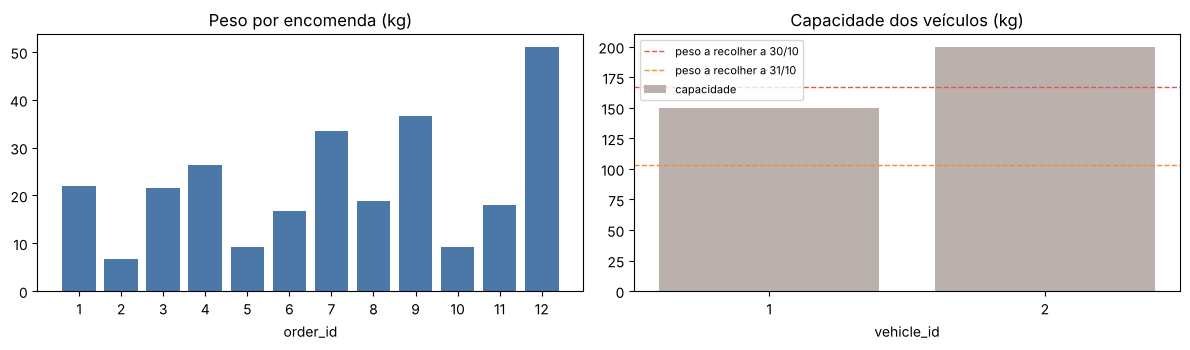

In [5]:
veh, cc = df["vehicles"], df["collection_centers"]
tot = it.weight_kg.sum()
print(f"Carga total: {tot:.1f} kg | capacidade da frota: {veh.capacity_kg.sum():.1f} kg ({tot / veh.capacity_kg.sum():.0%}) | "
      f"veículo mais pequeno: {veh.capacity_kg.min():.1f} kg | centro de recolha: {cc.capacity_kg.sum():.0f} kg")
day = it.groupby(it.availability_start.dt.strftime("%d/%m")).weight_kg.sum()
print("Peso a recolher por dia (kg):", day.round(1).to_dict())
w = it.groupby("order_id").weight_kg.sum()
print(f"Encomenda mais pesada: {w.max():.1f} kg | pedido mais pesado: {it.weight_kg.max():.1f} kg")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(w.index.astype(str), w.values, color="#4c78a8"); ax[0].set(title="Peso por encomenda (kg)", xlabel="order_id")
ax[1].bar(veh.vehicle_id.astype(str), veh.capacity_kg, color="#bab0ac", label="capacidade")
for d_, v_ in day.items():
    ax[1].axhline(v_, ls="--", lw=1, label=f"peso a recolher a {d_}", color="#e15759" if d_ == day.idxmax() else "#f28e2b")
ax[1].set(title="Capacidade dos veículos (kg)", xlabel="vehicle_id"); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

<p>A carga total é de 270 kg, 77% da capacidade da frota (350 kg), e a 30/10 há 166.9 kg para recolher, mais do que cabe no veículo 1 (150 kg). Ao contrário do dataset antigo, a <b>capacidade já pesa</b>: um veículo não leva tudo de uma vez e os dois veículos têm de partilhar o trabalho ou fazer mais do que uma viagem. O centro de recolha (5000 kg) nunca é limitativo, por isso não é modelado.</p>

<h2>6. Refrigeração</h2>

In [6]:
veh = df["vehicles"]
print("Veículos refrigerados:", int(veh.refrigerated.sum()), "de", len(veh))
display(veh[["vehicle_id", "plate", "capacity_kg", "refrigerated", "avg_speed_kmh"]])
cold_cols = [c for c in df["products"].columns if any(k in c.lower() for k in ("refrig", "cold", "frio"))]
print("Colunas de products que indicam frio:", cold_cols if cold_cols else "nenhuma")
print("Categorias de produtos:", df["products"].category.value_counts().to_dict())
print("Unidades:", df["products"].unit.value_counts().to_dict())

Veículos refrigerados: 1 de 2


,vehicle_id,plate,capacity_kg,refrigerated,avg_speed_kmh
0,1,ZG-06-DP,150.0,1,45.0
1,2,TY-74-YA,200.0,0,45.0


Colunas de products que indicam frio: nenhuma
Categorias de produtos: {'vegetable': 7, 'fruit': 6, 'other': 2}
Unidades: {'kg': 13, 'unit': 1, 'crate': 1}


<p>Há <b>1 veículo refrigerado em 2</b> (o veículo 1, de 150 kg). Os produtos só têm as categorias <i>vegetable</i>, <i>fruit</i> e <i>other</i> e <b>nenhuma coluna indica que um produto exige frio</b>. Conclusão: a restrição de refrigeração fica implementada no modelo (<code>Request.cold</code> e <code>Vehicle.refrigerated</code>, lida de uma coluna como <code>requires_refrigeration</code> se ela existir), mas <b>não está ativa</b> neste dataset. Se houvesse produtos que exigissem frio, só o veículo 1 os poderia levar, e com apenas 150 kg isso seria uma restrição forte.</p>

<h2>7. Velocidade</h2>

In [7]:
dm = df["distance_matrix"]
nz = dm[dm.duration_min > 0]
impl = nz.distance_km / nz.duration_min * 60
display(pd.DataFrame({"fonte": ["vehicles.avg_speed_kmh", "matriz (distance_km / duration_min)", "rules.csv"],
                      "km/h": [f"{df['vehicles'].avg_speed_kmh.min():g} a {df['vehicles'].avg_speed_kmh.max():g}",
                               f"{impl.min():.2f} a {impl.max():.2f}", f"{rules.avg_speed_kmh}"]}))

,fonte,km/h
0,vehicles.avg_speed_kmh,45 a 45
1,matriz (distance_km / duration_min),44.90 a 45.08
2,rules.csv,45.0


<p>As três fontes dão <b>45 km/h</b>: os veículos (<code>avg_speed_kmh</code>), a velocidade implícita da matriz (44.90 a 45.08 km/h, por arredondamento) e o <code>rules.csv</code>. Por isso usam se os tempos da matriz (<code>duration_min</code>) e não a velocidade do veículo: já estão calculados a 45 km/h e todos os veículos andam a essa velocidade. Se os veículos tivessem velocidades diferentes, bastaria escalar os tempos da matriz por veículo (melhoria futura).</p>

<h2>8. Geografia e matriz de distâncias</h2>

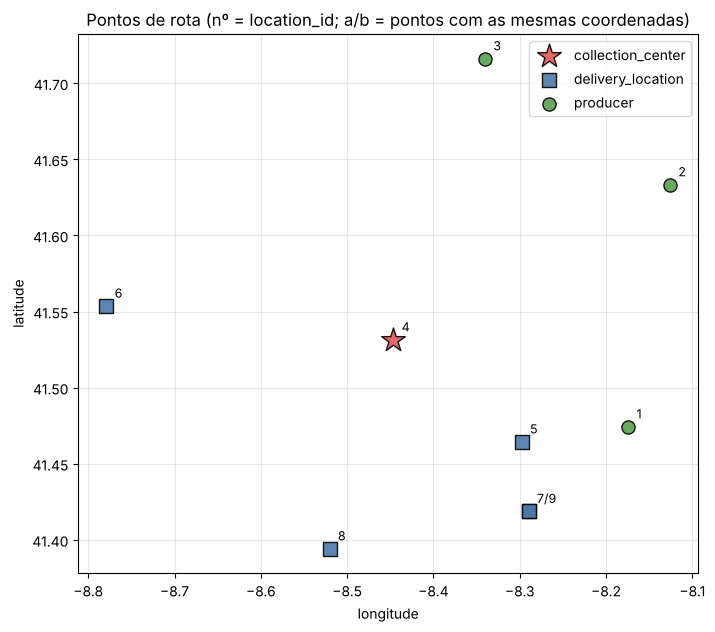

Pontos diferentes com as mesmas coordenadas:


,location_id,location_type,name,municipality
6,7,delivery_location,Casa 3,Guimaraes
8,9,delivery_location,Loja 5,Guimaraes


In [8]:
loc = df["locations"]
colors = {"producer": "#59a14f", "collection_center": "#e15759", "delivery_location": "#4c78a8"}
markers = {"producer": "o", "collection_center": "*", "delivery_location": "s"}
fig, ax = plt.subplots(figsize=(8, 7))
for tp, g in loc.groupby("location_type"):
    ax.scatter(g.longitude, g.latitude, c=colors[tp], marker=markers[tp], s=320 if tp == "collection_center" else 90, label=tp, edgecolor="k",
               zorder=4 if tp == "collection_center" else 3, alpha=0.9)
for (la, lo), g in loc.groupby(["latitude", "longitude"]):
    ax.annotate("/".join(map(str, g.location_id)), (lo, la), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.set(title="Pontos de rota (nº = location_id; a/b = pontos com as mesmas coordenadas)", xlabel="longitude", ylabel="latitude")
ax.legend(); ax.grid(alpha=.3); plt.show()
same = loc[loc.duplicated(["latitude", "longitude"], keep=False)].sort_values(["latitude", "location_id"])
print("Pontos diferentes com as mesmas coordenadas:")
display(same[["location_id", "location_type", "name", "municipality"]])

<p>Os pontos ficam entre Esposende e Fafe, e o centro de recolha (location 4, Braga) fica no meio, a 19 a 38 km dos restantes. Os locais de entrega 7 (Casa 3) e 9 (Loja 5) têm as mesmas coordenadas, em Guimarães, mas <code>location_id</code> diferentes. No modelo uma paragem é definida pelo <code>location_id</code>, por isso entregar nos dois são duas paragens (a 0 km uma da outra), cada uma com o seu serviço de 10 min.</p>

Pares: 72 (esperado 9x8 = 72) | pares duplicados: 0
Simétrica (distância): True | simétrica (tempo): True
Fator de estrada (distance_km / linha reta): 1.300 a 1.300 (rules.csv: 1.3)
Pares a 0 km: [[7, 9], [9, 7]]
Violações da desigualdade triangular: 0 (excesso máximo 0.00 km, arredondamento das distâncias a 0.01 km)
Centro (4) até aos restantes pontos (km): {1: 30.6, 2: 37.7, 3: 29.1, 5: 18.8, 6: 36.1, 7: 23.5, 8: 21.4, 9: 23.5}


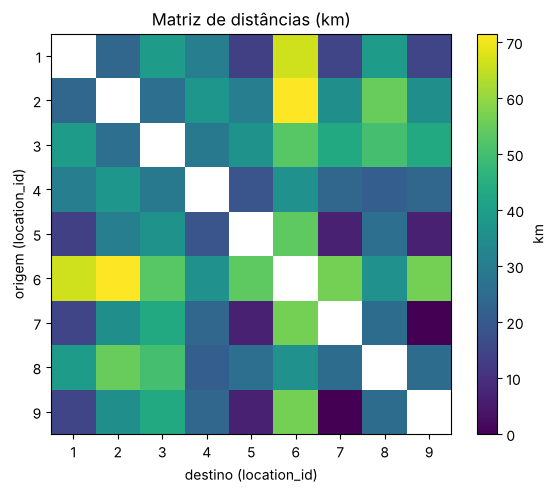

In [9]:
n = len(loc)
print(f"Pares: {len(dm)} (esperado {n}x{n-1} = {n*(n-1)}) | pares duplicados: {dm.duplicated(['origin_location_id', 'destination_location_id']).sum()}")
M = dm.pivot(index="origin_location_id", columns="destination_location_id", values="distance_km")
Tm = dm.pivot(index="origin_location_id", columns="destination_location_id", values="duration_min")
print("Simétrica (distância):", np.allclose(M.fillna(0), M.fillna(0).T), "| simétrica (tempo):", np.allclose(Tm.fillna(0), Tm.fillna(0).T))

def hav(a, b):
    R = 6371.0; p1, p2 = np.radians(a[0]), np.radians(b[0]); dphi = p2 - p1; dl = np.radians(b[1] - a[1])
    return 2 * R * np.arcsin(np.sqrt(np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2))
xy = loc.set_index("location_id")[["latitude", "longitude"]].to_dict("index")
dm["straight_km"] = [hav((xy[o]["latitude"], xy[o]["longitude"]), (xy[d]["latitude"], xy[d]["longitude"])) for o, d in zip(dm.origin_location_id, dm.destination_location_id)]
nzd = dm[dm.straight_km > 0.01]
print(f"Fator de estrada (distance_km / linha reta): {(nzd.distance_km / nzd.straight_km).min():.3f} a {(nzd.distance_km / nzd.straight_km).max():.3f} (rules.csv: {rules.route_factor})")
print("Pares a 0 km:", dm[dm.distance_km == 0][["origin_location_id", "destination_location_id"]].values.tolist())
A = M.fillna(0).values; viol, excess = 0, 0.0
for i in range(n):
    for j in range(n):
        for k in range(n):
            if len({i, j, k}) == 3 and A[i, j] > A[i, k] + A[k, j] + 1e-9:
                viol += 1; excess = max(excess, A[i, j] - A[i, k] - A[k, j])
print(f"Violações da desigualdade triangular: {viol} (excesso máximo {excess:.2f} km, arredondamento das distâncias a 0.01 km)")
CENTER = int(loc[loc.location_type == "collection_center"].location_id.iloc[0])
print(f"Centro ({CENTER}) até aos restantes pontos (km):", M.loc[CENTER].dropna().round(1).to_dict())
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(M.values, cmap="viridis"); plt.colorbar(im, label="km")
ax.set_xticks(range(n), M.columns); ax.set_yticks(range(n), M.index)
ax.set(title="Matriz de distâncias (km)", xlabel="destino (location_id)", ylabel="origem (location_id)"); plt.show()

<p>A matriz é completa e simétrica, com fator de estrada 1.3 sobre a linha reta e velocidade de 45 km/h, e respeita a desigualdade triangular. Isto justifica as heurísticas admissíveis do A* e o limite inferior do <i>branch &amp; bound</i> do CSP (acrescentar uma paragem nunca reduz a distância).</p>

<h2>9. Viabilidade de cada pedido no melhor caso</h2>

S = 10 min, H = 15 min | pedidos que cumprem a janela no melhor caso: 40 de 40
Folga no melhor caso: mínimo 90 min, mediana 150 min


,order_item_id,order_id,p,d,availability_start,delivery_start,delivery_end,travel_min,slack_min
24,25,9,1,9,2026-10-30 07:45:00,2026-10-31 08:15:00,2026-10-31 09:45:00,72.2,90.0
25,26,9,3,9,2026-10-30 08:00:00,2026-10-31 08:15:00,2026-10-31 09:45:00,70.1,90.0
26,27,9,2,9,2026-10-30 08:15:00,2026-10-31 08:15:00,2026-10-31 09:45:00,81.6,90.0
27,28,9,2,9,2026-10-30 08:30:00,2026-10-31 08:15:00,2026-10-31 09:45:00,81.6,90.0
28,29,9,3,9,2026-10-30 07:15:00,2026-10-31 08:15:00,2026-10-31 09:45:00,70.1,90.0


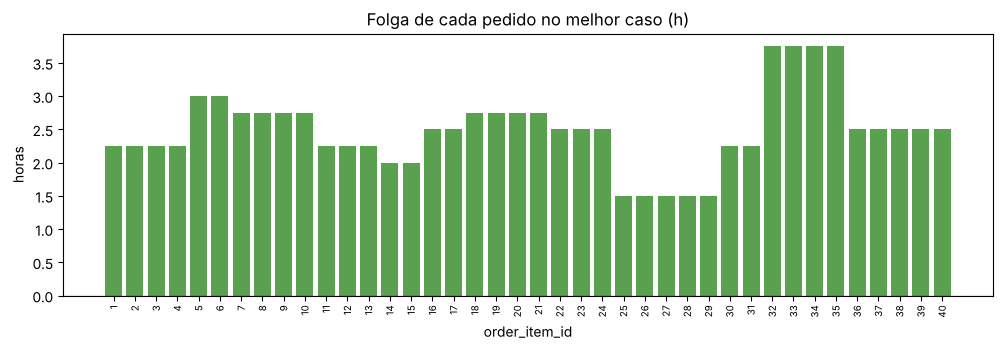

In [10]:
# Melhor caso de cada pedido com as regras: recolha no início da janela, serviço S, viagem até ao armazém, manuseamento H,
# viagem até ao cliente; sem esperas além das janelas
S, H = rules.stop_service_min, rules.warehouse_handling_min
loc_p = loc[loc.location_type == "producer"].set_index("ref_id").location_id
loc_d = loc[loc.location_type == "delivery_location"].set_index("ref_id").location_id
Dt = dm.set_index(["origin_location_id", "destination_location_id"]).duration_min
it["p"], it["d"] = it.producer_id.map(loc_p), it.delivery_location_id.map(loc_d)
it["travel_min"] = [Dt[(p, CENTER)] + Dt[(CENTER, d)] for p, d in zip(it.p, it.d)]
it["earliest_delivery"] = [max(a + pd.Timedelta(minutes=S + m + H), e) for a, m, e in zip(it.availability_start, it.travel_min, it.delivery_start)]
it["slack_min"] = (it.delivery_end - it.earliest_delivery).dt.total_seconds() / 60
print(f"S = {S:g} min, H = {H:g} min | pedidos que cumprem a janela no melhor caso: {(it.slack_min >= 0).sum()} de {len(it)}")
print(f"Folga no melhor caso: mínimo {it.slack_min.min():.0f} min, mediana {it.slack_min.median():.0f} min")
display(it.nsmallest(5, "slack_min")[["order_item_id", "order_id", "p", "d", "availability_start", "delivery_start", "delivery_end", "travel_min", "slack_min"]])
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.bar(it.order_item_id.astype(str), it.slack_min / 60, color=np.where(it.slack_min < 0, "#e15759", "#59a14f"))
ax.axhline(0, color="k", lw=.8); ax.set(title="Folga de cada pedido no melhor caso (h)", xlabel="order_item_id", ylabel="horas")
ax.tick_params(axis="x", labelsize=7, rotation=90); plt.show()

<p>Com as regras novas, o melhor caso de cada pedido é recolher no início da janela, 10 min de serviço, viagem até ao armazém, 15 min de manuseamento e viagem até ao cliente. Assim, <b>os 40 pedidos cumprem a janela de entrega no melhor caso</b>, com uma folga mínima de 90 min. Ao contrário do dataset antigo, não há atrasos inevitáveis: qualquer atraso numa solução resulta de conflitos entre pedidos (os dois veículos não conseguem estar em todo o lado à hora certa).</p>

<h2>10. Estrutura temporal</h2>

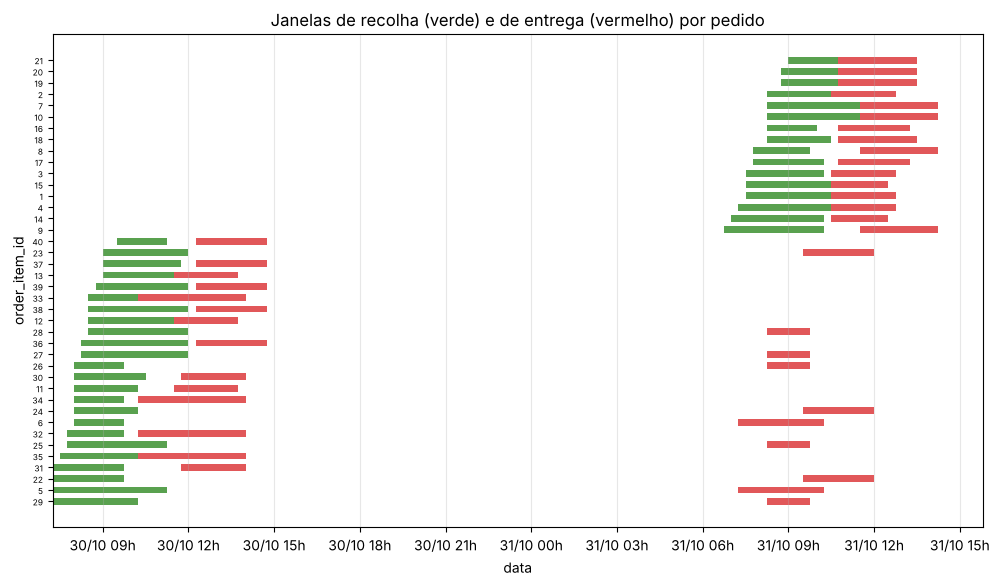

1 grupo(s) temporal(is); tamanhos: [40]


dia_entrega,30/10,31/10,total
dia_recolha,,,
30/10,14,10,24
31/10,0,16,16
total,14,26,40


In [11]:
s = it.sort_values("availability_start").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, max(5, len(s) * 0.16)))
for i, r in s.iterrows():
    ax.barh(i, mdates.date2num(r.availability_end) - mdates.date2num(r.availability_start), left=mdates.date2num(r.availability_start), color="#59a14f", height=.6)
    ax.barh(i, mdates.date2num(r.delivery_end) - mdates.date2num(r.delivery_start), left=mdates.date2num(r.delivery_start), color="#e15759", height=.6)
ax.set_yticks(range(len(s)), s.order_item_id, fontsize=6); ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
ax.set(title="Janelas de recolha (verde) e de entrega (vermelho) por pedido", xlabel="data", ylabel="order_item_id"); ax.grid(axis="x", alpha=.3); plt.show()

# Grupos de pedidos que não interferem entre si (a mesma regra de agent.temporal_groups: margem = viagem mais longa + 2 h)
margin = pd.Timedelta(minutes=dm.duration_min.max() + 120)
groups, cur, end = [], [], None
for r in s.itertuples():
    if cur and r.availability_start > end + margin:
        groups.append(cur); cur = []
    end = r.delivery_end if not cur else max(end, r.delivery_end)
    cur.append(r.order_item_id)
groups.append(cur)
print(len(groups), "grupo(s) temporal(is); tamanhos:", [len(g) for g in groups])
sem = s.copy(); sem["dia_recolha"] = sem.availability_start.dt.strftime("%d/%m"); sem["dia_entrega"] = sem.delivery_start.dt.strftime("%d/%m")
display(pd.crosstab(sem.dia_recolha, sem.dia_entrega, margins=True, margins_name="total"))

<p>Há só 2 dias, com janelas que se sobrepõem e pedidos que atravessam a noite, e a regra de <code>agent.temporal_groups</code> junta os <b>40 pedidos num único grupo</b>. Consequência para a pesquisa: deixa de ser possível partir o problema em pedaços pequenos. O A* tem de lidar com 40 pedidos de uma vez, o que é impossível (o espaço de estados cresce exponencialmente), por isso no notebook principal o A* é comparado em sub instâncias de tamanho crescente e a solução completa vem do Greedy, do Hill Climbing e do CSP.</p>

<h2>11. Conclusões</h2>
<ul><li><b>Regras novas (<code>rules.csv</code>):</b> o modelo passa a lê las. O serviço é cobrado <b>por paragem</b> (10 min), o armazém tem um manuseamento de 15 min e um limite de 24 h, a origem do tempo é a meia noite de 30/10 e as janelas limitam o início do serviço.</li><li><b>Integridade:</b> dados consistentes; <code>weight_kg</code> é usado diretamente.</li><li><b>Janelas:</b> coerentes, dentro de 2 dias; 10 pedidos são entregues no dia seguinte, com intervalos até 23.75 h, abaixo do limite de 24 h.</li><li><b>Capacidade:</b> 270 kg para 350 kg de frota; a 30/10 há mais carga do que cabe no veículo refrigerado, por isso a capacidade passa a ser uma restrição ativa.</li><li><b>Refrigeração:</b> 1 veículo refrigerado em 2, mas nenhum produto marcado como exigindo frio; a restrição está no modelo mas não está ativa.</li><li><b>Velocidade:</b> 45 km/h nas três fontes; usam se os tempos da matriz.</li><li><b>Matriz:</b> simétrica, fator 1.3, desigualdade triangular cumprida; dois locais de entrega com as mesmas coordenadas.</li><li><b>Viabilidade:</b> todos os pedidos cumprem a janela no melhor caso (folga mínima de 90 min).</li><li><b>Estrutura temporal:</b> um só grupo de 40 pedidos; o A* só é viável em sub instâncias pequenas.</li></ul>